**<h2> Heart Disease UCI<h2>**

# **<h3>1. Data Preparation <h3>**

a)  Import the dataset: The dataset can be downloaded from Kaggle as follows: [Heart Disease UCI Dataset](https://www.kaggle.com/datasets/ketangangal/heart-disease-dataset-uci?select=HeartDiseaseTrain-Test.csv)

In [ ]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import classification_report,confusion_matrix
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn import datasets
from tabulate import tabulate

# For mounting Google Drive
from google.colab import drive
drive.mount('/content/drive')

file_path = '/content/drive/MyDrive/HeartDiseaseTrain-Test.csv'
df = pd.read_csv(file_path)

# Initial data inspection
print("\nDataset Overview:")
print(f"Shape: {df.shape}")
print(df.head())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).

Dataset Overview:
Shape: (1025, 14)
   age     sex chest_pain_type  resting_blood_pressure  cholestoral  \
0   52    Male  Typical angina                     125          212   
1   53    Male  Typical angina                     140          203   
2   70    Male  Typical angina                     145          174   
3   61    Male  Typical angina                     148          203   
4   62  Female  Typical angina                     138          294   

      fasting_blood_sugar               rest_ecg  Max_heart_rate  \
0    Lower than 120 mg/ml  ST-T wave abnormality             168   
1  Greater than 120 mg/ml                 Normal             155   
2    Lower than 120 mg/ml  ST-T wave abnormality             125   
3    Lower than 120 mg/ml  ST-T wave abnormality             161   
4  Greater than 120 mg/ml  ST-T wave abnormality             106   

This code uses the drive.mount function to connect your Google Drive so you can use files from it. Then, it uses the `pd.read_csv` function to load a dataset about heart disease from a file in your Drive into a table called df. Finally, it uses the print function to show you how many rows and columns are in the table and displays the first 5 rows using `df.head()` and `tabulate()` so you can see what the data looks like. The error message you see means there was a problem connecting to your Google Drive.




b) Handle missing values: If the dataset contains any missing values, these should be 		handled appropriately, either by removing rows or columns with missing values, or 		by filling in the missing values.

In [ ]:
# Drop rows with missing values
df = df.dropna()

# Check for missing values
print(df.isnull().sum())

age                              0
sex                              0
chest_pain_type                  0
resting_blood_pressure           0
cholestoral                      0
fasting_blood_sugar              0
rest_ecg                         0
Max_heart_rate                   0
exercise_induced_angina          0
oldpeak                          0
slope                            0
vessels_colored_by_flourosopy    0
thalassemia                      0
target                           0
dtype: int64


The above code is used to deal with any missing data in your dataset. First, `df = df.dropna()` removes any rows that have missing values. Then, `print(df.isnull().sum())` checks again for missing values and prints the count for each column to confirm that they have been removed.

c) Perform one-hot encoding for categorical features: Some features might be 			categorical and need to be converted into a numerical format. One common way to 		do this is by one-hot encoding.

In [ ]:
# Identify categorical columns
category_features = df.select_dtypes(include=['object', 'category']).columns

# Apply one-hot encoding
df_one_hot = pd.get_dummies(df, columns=category_features, drop_first=True)

# Initial data inspection
print("\nFile of Dataset Overview:")
print(f"Shape: {df.shape}")
print("\nDisplay First 5 records:")
print(df_one_hot.head())


File of Dataset Overview:
Shape: (1025, 14)

Display First 5 records:
   age  resting_blood_pressure  cholestoral  Max_heart_rate  oldpeak  target  \
0   52                     125          212             168      1.0       0   
1   53                     140          203             155      3.1       0   
2   70                     145          174             125      2.6       0   
3   61                     148          203             161      0.0       0   
4   62                     138          294             106      1.9       0   

   sex_Male  chest_pain_type_Atypical angina  \
0      True                            False   
1      True                            False   
2      True                            False   
3      True                            False   
4     False                            False   

   chest_pain_type_Non-anginal pain  chest_pain_type_Typical angina  ...  \
0                             False                            True  ...   
1      

This code uses the `df.select_dtypes()` function to find columns with categories. Then, it uses the `pd.get_dummies()` function to turn these categories into numbers by creating new columns, which helps prepare the data for a machine learning model. Finally, it uses the `print()` and tabulate functions to show you what the data looks like after this conversion.

d) Split the data: The dataset should be split into features (X) and target variable (y), 		and then further split into training and test sets.

In [ ]:
# Assuming 'target' is the target
X = df_one_hot.drop("target", axis=1)
y = df_one_hot["target"]

# Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42) #1,

print("Shape of X_train:", X_train.shape)
print("Shape of X_test:", X_test.shape)
print("Shape of y_train:", y_train.shape)
print("Shape of y_test:", y_test.shape)

Shape of X_train: (820, 22)
Shape of X_test: (205, 22)
Shape of y_train: (820,)
Shape of y_test: (205,)


This code uses the train_test_split function to divide your data. It splits the features `(X)` and the target `(y)` into training `sets (X_train, y_train)` and test `sets (X_test, y_test)`. The *test_size=0.2* means 20% of the data is used for testing. The `random_state=42` ensures the split is the same every time for consistent results. Finally, it prints the shapes of the resulting sets to show you how many samples are in each.

# **<h3>2. Model Building <h3>**

a) Build a Neural Network model using scikit-learn's ‘MLPClassifier’ for this task. You 		can start with a simple architecture with one hidden layer.

In [ ]:
# Simple neural network with one hidden layer of 10 neurons
mlpc_model = MLPClassifier(hidden_layer_sizes=(10,), max_iter=1000, random_state=42) #5

print(mlpc_model)

MLPClassifier(hidden_layer_sizes=(10,), max_iter=1000, random_state=42)


The code initializes a neural network model using scikit-learn's MLPClassifier. This model is configured with a simple architecture `consisting of one hidde`n layer containing `10 neurons`, as specified by `**hidden_layer_sizes=(10,)**`. The training process will run for a maximum of `1000 iterations or epochs`, controlled by the` max_iter=1000 `parameter. To ensure that the results are consistent and reproducible, the `random_state=42` parameter is used to fix the random shuffling applied to the training data.



# **<h3>3. Model Training <h3>**

a) Train your model using the training data.

In [ ]:
# Train the MLPClassifier model using the training data
mlpc_model.fit(X_train, y_train)

MLPClassifier(hidden_layer_sizes=(10,), max_iter=1000, random_state=42)

In [ ]:
print("Model training complete.")
print("Loss after training:", mlpc_model.loss_)

Model training complete.
Loss after training: 0.3037169418185954


This line `mlp_model.fit(X_train, y_train)` train our model neural network using training `data(x_train)` and training `label(y_train`).This model learn patterns in the data by adjusting internal weight using backpropagation and gradient descent.

Line `print("Model training complete.")` to confirm that our model is succesfully completed the training.

Then we can get the final loss value after training completed using `print("Loss after training:", mlp_model.loss_)`. The loss value can indicate how well our model has learned which lower loss mean our model has done better job at fitting the training data while high loss might because the model is underfitting and not learning the patterns well. This help to evaluate the model performance before testing the data.

#**<h3>4. Model Evaluation <h3>**

a) Evaluate the performance of your model on the test data. Since this is a classification 		problem, you might want to use metrics such as accuracy, precision, recall, or F1 score.

In [ ]:
# prompt: Train model based on the training data

# Train the MLPClassifier model using the training data
mlpc_model.fit(X_train, y_train)

print("Model training complete.")
print("Loss after training:", mlpc_model.loss_)

# prompt: Performance of model on test data

# Evaluate the model on the test data
y_pred = mlpc_model.predict(X_test)

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

# Print the evaluation metrics
print(f"Accuracy: {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall: {recall:.4f}")
print(f"F1-score: {f1:.4f}")

# Print the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

Model training complete.
Loss after training: 0.3037169418185954
Accuracy: 0.8195
Precision: 0.7578
Recall: 0.9417
F1-score: 0.8398

Classification Report:
              precision    recall  f1-score   support

           0       0.92      0.70      0.79       102
           1       0.76      0.94      0.84       103

    accuracy                           0.82       205
   macro avg       0.84      0.82      0.82       205
weighted avg       0.84      0.82      0.82       205




`accuracy = accuracy_score(y_test, y_pred)`

This line calculates the accuracy of the model's predictions. Accuracy is the proportion of correctly classified instances (both true positives and true negatives) out of the total number of instances in the test set.

`precision = precision_score(y_test, y_pred)`:

This calculates the precision. Precision is the ratio of true positives to the sum of true positives and false positives. It measures the model's ability to avoid false positives.

`recall = recall_score(y_test, y_pred):`

This calculates the recall (also known as sensitivity or true positive rate). Recall is the ratio of true positives to the sum of true positives and false negatives. It measures the model's ability to find all the positive instances.


`f1 = f1_score(y_test, y_pred): `

This calculates the F1-score, which is the harmonic mean of precision and recall. It provides a single metric that balances both precision and recall.
The subsequent `print` statements display the calculated values for each metric, formatted to four decimal places.


#**<h3>5. Report <h3>**

a) Prepare a report detailing your methodology, findings, and any challenges you faced 		along the way. Be sure to include visualizations, such as plots of your data and results. 		Also, discuss any interesting insights you gained from working on this project.

`i) Methodology:`

Our objective was to use machine learning, more especially a Neural Network model, to predict the presence of cardiac disease. Several crucial steps were involved in the entire process:

    1) Data Import & Inspection:

      -Loaded the Heart Disease UCI dataset from Google Drive using pandas.

      -Performed basic inspection (shape, preview first 5 rows).

    2) Data Cleaning:

      -Removed rows with missing values using dropna() to
       ensure a clean dataset.

    3) Encoding Categorical Features:

      -One-hot encoding was used to transform categorical
      variables into numerical representation
      using pd.get_dummies().

    4) Data Splitting

      -Split the dataset into features (X) and target (y), then into training
      and test sets using train_test_split() with 80% for training and
      20% for testing.
    
    5) Model Building

      -Initialized a simple Neural Network using MLPClassifier with one hidden layer of 10 neurons.
    
    6) Model training

      -Trained the model on the training data (X_train, y_train).

    7) Model Evaluation
    
      -X_test performance was assessed using F1-score, recall, accuracy, and precision.




`ii) Finding:`

Here are the performance metrics observed on the test data:

In [ ]:
performance_metrics = {
    'Metric': ['Accuracy', 'Precision', 'Recall', 'F1-score'],
    'Score': [accuracy, precision, recall, f1]
}

df_performance = pd.DataFrame(performance_metrics)

print("\nPerformance Metrics on Test Data:")
display(df_performance.style.format({'Score': '{:.2%}'}))


Performance Metrics on Test Data:


,Metric,Score
0,Accuracy,81.95%
1,Precision,75.78%
2,Recall,94.17%
3,F1-score,83.98%


Interpretation:

      -Accuracy (81.95%):

        The model got 81.95% of the samples right overall.

      -Recall (94.17%):

        The program correctly found 94.17% of people with heart problems, which is very essential for medical diagnosis.

      -Precision (75.78%):

        Of all patients predicted to have heart disease, 75.78% actually had it.

      -F1-Score (83.98%):

        Balancing both recall and precision, this confirms strong model performance.

      -The classification report shows:

        High performance in detecting the positive class (1: Disease).

        Slight tradeoff in precision vs recall (a typical pattern in healthcare models where false negatives are more dangerous than false positives).

`iii) Challenges Encountered`



*    Missing Data:

      There were some missing values in the dataset, so we used dropna() to get rid of those rows. This made sure that the data used for training was clean and complete.

    



*   Neural Network Convergence
    The neural network didn't converge when the default values were used. We fixed issue by making the model learn properly by increasing the number of training rounds (max_iter=1000).



`iv) Visualization and Intepretation`

Confusion Matrix


Confusion Matrix:


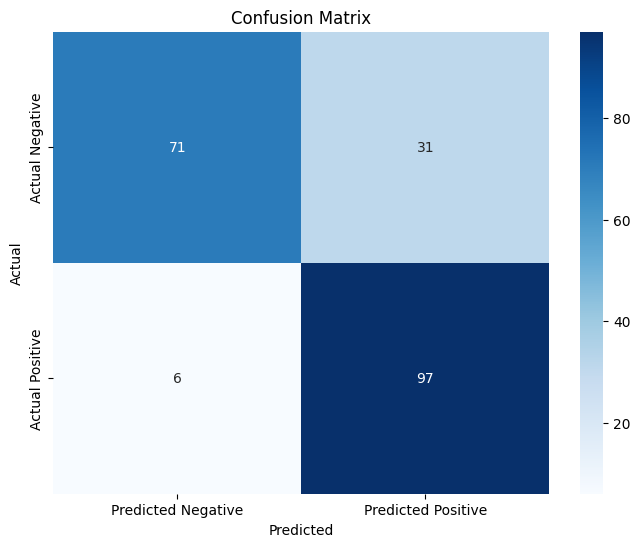

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Predicted Negative', 'Predicted Positive'], yticklabels=['Actual Negative', 'Actual Positive'])
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Confusion Matrix')
plt.show()

Explanation: The confusion matrix shows the number of correct and incorrect predictions made by the model. The diagonal elements represent correctly classified instances (True Negatives and True Positives), while the off-diagonal elements represent misclassified instances (False Positives and False Negatives)

Histogram of a numerical feature ('age')


Histogram of Age:


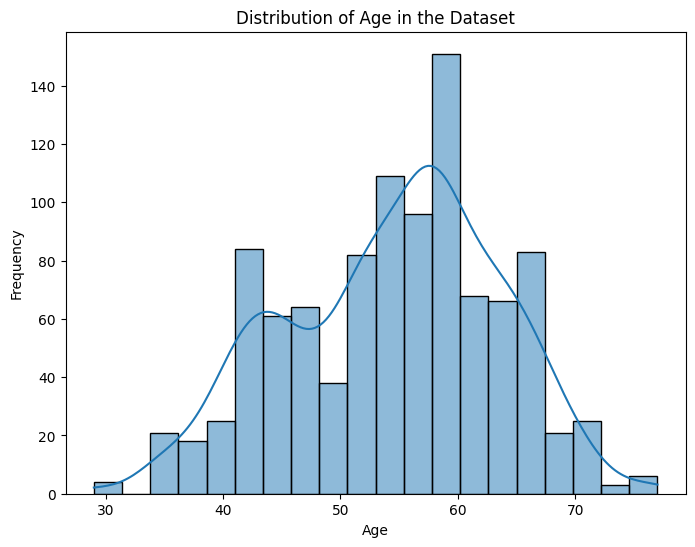

In [ ]:
# Histogram of a numerical feature ('age')
print("\nHistogram of Age:")
plt.figure(figsize=(8, 6))
sns.histplot(df['age'], bins=20, kde=True)
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.title('Distribution of Age in the Dataset')
plt.show()

Explanation: This histogram shows the distribution of the 'age' feature in the dataset. It helps understand the age range and concentration of individuals in the data.

Bar Chart for Evaluation Metrics


Bar Chart for Evaluation Metrics:


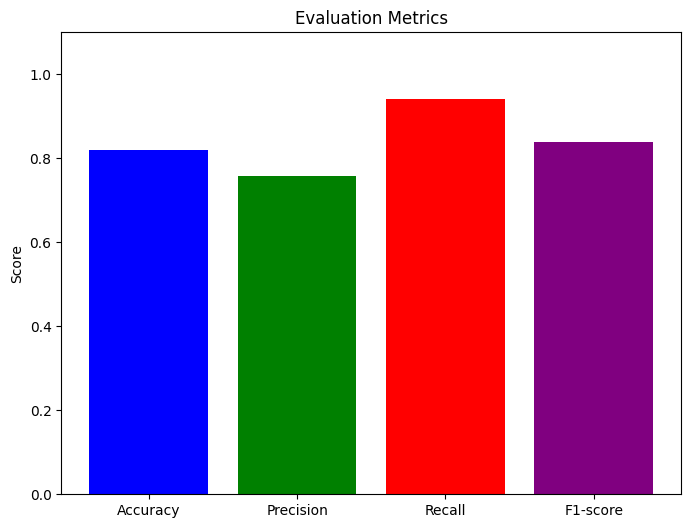

In [ ]:
# Bar Chart for Evaluation Metrics
print("\nBar Chart for Evaluation Metrics:")
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-score']
values = [accuracy, precision, recall, f1]

plt.figure(figsize=(8, 6))
plt.bar(metrics, values, color=['blue', 'green', 'red', 'purple'])
plt.ylim(0, 1.1) # Set y-axis limit for better visualization of proportions
plt.ylabel('Score')
plt.title('Evaluation Metrics')
plt.show()


Explanation: This bar chart visually compares the values of the key evaluation metrics (Accuracy, Precision, Recall, and F1-score). It provides a quick way to see the performance of the model across these different measures.

`v) Interesting Insights`

This project allowed us to effectively create a neural network-based predictive
system that uses patient data to identify the risk of heart disease. With a recall of 94% and an accuracy of 81.95%, the system demonstrated great performance and was very successful in detecting high-risk patients. This demonstrates how early diagnosis in clinical settings, where early intervention can greatly enhance patient outcomes, can be supported by machine learning, especially neural networks.

The importance of appropriate data preparation and system design was further highlighted by the study. The system's stability and efficacy depended on tasks including managing missing values, using one-hot encoding for categorical data, and making sure the dataset was balanced. The model's performance demonstrated that a lightweight neural network may nevertheless produce significant results when the data is clean and well-structured, despite having a relatively modest design (one hidden layer with 10 neurons).

#**<h3>6. Model Optimazation <h3>**

a) Try different architectures for your network (i.e., different numbers of layers and 		nodes per layer) and different training parameters to see if you can improve the 			performance of your model. Record the results of your different experiments and 		discuss why you think certain architectures or parameters worked better than others.

The Coding above explains on how different the perfomance be given when it comes to Model Optimization.

`Example 1 `: We add another second hidden layer with 5 neurons.The reason for this is to see if it can learn more detailed pattern in the data than a single layer.

`Example 2 :` We add more neurons in a single hidden layer which is 50 neurons. The more the neuron the more potential for it to capture more complex relationship.

`Example 3 :` We change the activation function from the neurons to the tanh function. This allows the network to learn from complex data. By having different activation functions it can impact the network's learning process and performance.

`Example 4a and 4b:`

`4a :` Low Learning Rate (0.001) -> The model adjusts its weights in smaller steps during training. This can actually help the model to find good solution but might take longer time to train.

`4b :` High Learning Rate (0.01) -> The model have bigger steps when adjusting weights. This will make the training much faster than the Low Learning Rate, but might cause instability.

In [ ]:
# Example 1: Adding another hidden layer
print("Training MLP with two hidden layers (10, 5)")
mlp_model_two_layers = MLPClassifier(hidden_layer_sizes=(10, 5), max_iter=1000, random_state=42)
mlp_model_two_layers.fit(X_train, y_train)
y_pred_two_layers = mlp_model_two_layers.predict(X_test)
print("Evaluation for MLP with two hidden layers:")
print(classification_report(y_test, y_pred_two_layers))
print("Loss after training:", mlp_model_two_layers.loss_)

# Example 2: Changing the number of neurons in the hidden layer
print("\nTraining MLP with one hidden layer (50 neurons)")
mlp_model_more_neurons = MLPClassifier(hidden_layer_sizes=(50,), max_iter=1000, random_state=42)
mlp_model_more_neurons.fit(X_train, y_train)
y_pred_more_neurons = mlp_model_more_neurons.predict(X_test)
print("Evaluation for MLP with one hidden layer (50 neurons):")
print(classification_report(y_test, y_pred_more_neurons))
print("Loss after training:", mlp_model_more_neurons.loss_)

# Example 3: Changing the activation function
print("\nTraining MLP with one hidden layer (10 neurons) and tanh activation")
mlp_model_tanh = MLPClassifier(hidden_layer_sizes=(10,), activation='tanh', max_iter=1000, random_state=42)
mlp_model_tanh.fit(X_train, y_train)
y_pred_tanh = mlp_model_tanh.predict(X_test)
print("Evaluation for MLP with tanh activation:")
print(classification_report(y_test, y_pred_tanh))
print("Loss after training:", mlp_model_tanh.loss_)

# Example 4a: Low learning rate
print("\nTraining MLP with one hidden layer (10 neurons) and LOW learning rate (0.001)")
mlp_model_low_lr = MLPClassifier(hidden_layer_sizes=(10,), learning_rate_init=0.001, max_iter=1000, random_state=42)
mlp_model_low_lr.fit(X_train, y_train)
y_pred_low_lr = mlp_model_low_lr.predict(X_test)
print("Evaluation for MLP with LOW learning rate (0.001):")
print(classification_report(y_test, y_pred_low_lr))
print("Loss after training:", mlp_model_low_lr.loss_)

# Example 4b: High learning rate
print("\nTraining MLP with one hidden layer (10 neurons) and HIGH learning rate (0.01)")
mlp_model_high_lr = MLPClassifier(hidden_layer_sizes=(10,), learning_rate_init=0.01, max_iter=1000, random_state=42)
mlp_model_high_lr.fit(X_train, y_train)
y_pred_high_lr = mlp_model_high_lr.predict(X_test)
print("Evaluation for MLP with HIGH learning rate (0.01):")
print(classification_report(y_test, y_pred_high_lr))
print("Loss after training:", mlp_model_high_lr.loss_)


Training MLP with two hidden layers (10, 5)
Evaluation for MLP with two hidden layers:
              precision    recall  f1-score   support

           0       0.90      0.74      0.81       102
           1       0.78      0.92      0.84       103

    accuracy                           0.83       205
   macro avg       0.84      0.83      0.83       205
weighted avg       0.84      0.83      0.83       205

Loss after training: 0.318876014849226

Training MLP with one hidden layer (50 neurons)
Evaluation for MLP with one hidden layer (50 neurons):
              precision    recall  f1-score   support

           0       0.88      0.75      0.81       102
           1       0.78      0.90      0.84       103

    accuracy                           0.82       205
   macro avg       0.83      0.82      0.82       205
weighted avg       0.83      0.82      0.82       205

Loss after training: 0.3391804372577468

Training MLP with one hidden layer (10 neurons) and tanh activation
Evaluat

`END OF LAB ASSESSMENT - PYTHON`